# 06: Outlier Analysis: Which Texts Are Hard, and Which Method Handles Them Best?

**Why this notebook:** all scores so far are averages over every text. But some texts are unusual (very short, ambiguous or off-topic), and they may be much harder to cluster than the rest. This notebook checks:
1. **Which texts are outliers**, found without using the true labels.
2. **What they look like:** length, examples, categories.
3. **How much they lower the scores** of each method.
4. **Which method handles them best:** the original LLM method, our improved method, or K-means.

**Definition of an outlier:** a text whose meaning is far from all other texts. We embed every text with E5-large (saved in notebook 03) and compute its **average cosine distance to its 10 nearest neighbors**. A high distance means no other text is similar to it. The **top 5% and 10%** by this score are the outliers. This is a standard, label-free outlier score, so it could be used in a real setting.

**No new LLM calls:** we reuse the saved predictions from notebooks 01 and 02, and recompute K-means (seconds).

## 0. Setup
Same configs as notebook 05: each dataset and model with the threshold chosen in notebook 02.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
import evaluate as ev
import given_label_classification as glc

SIZE = "small"
CONFIGS = [("massive_scenario", "qwen2.5:7b", 0.5),
           ("massive_scenario", "qwen3:8b", 0.6),
           ("massive_intent", "qwen2.5:7b", 0.4)]
NAMES = {"massive_scenario": "Massive-D", "massive_intent": "Massive-I"}
K_NEIGHBORS = 10
OUTLIER_SHARES = [0.05, 0.10]

def out_dir(model):
    return "./generated_labels" if model == "qwen2.5:7b" else f"./generated_labels/{model.replace(':', '_')}"

os.makedirs("./results/figures", exist_ok=True)
os.makedirs("./results/tables", exist_ok=True)

## 1. Load data, embeddings and every method's predictions
For each config we collect, per text:
- **Original method:** the baseline classification from notebook 01. Texts it could not classify are labelled "Unsuccessful", as in its scores.
- **Ours (A+B+C):** the saved answers from notebook 02, with strict matching + rescue (Fix C).
- **K-means E5 (true K)** and **K-means E5 (same K as ours):** recomputed here on the same embeddings.

In [2]:
from sentence_transformers import SentenceTransformer
minilm = SentenceTransformer("all-MiniLM-L6-v2")
def embed_labels(items):
    return minilm.encode([str(x).replace("_", " ") for x in items], normalize_embeddings=True)

def answer_text(raw):
    try:
        obj = glc.parse_json(raw)
        vals = [v for v in obj.values() if isinstance(v, str)]
        return vals[0] if vals else str(raw)
    except Exception:
        return str(raw or "")

def load_ours(data, model, t):
    out = out_dir(model)
    with open(f"{out}/{data}_{SIZE}_improved_labels_t{t}.json", encoding="utf-8") as f:
        labels = json.load(f)
    raw = {}
    with open(f"{out}/{data}_{SIZE}_improved_t{t}_raw.jsonl", encoding="utf-8") as f:
        for line in f:
            r = json.loads(line); raw[r["i"]] = r["raw"]
    raw = [raw[i] for i in range(len(raw))]
    preds = [glc.answer_process(r, labels) if r else "Unsuccessful" for r in raw]
    failed = [i for i, p in enumerate(preds) if p == "Unsuccessful"]
    if failed:
        E_lab = embed_labels(labels); E_ans = embed_labels([answer_text(raw[i]) for i in failed])
        for i, j in zip(failed, (E_ans @ E_lab.T).argmax(axis=1)):
            preds[i] = labels[j]
    return preds

def load_original(data, model, texts):
    with open(f"{out_dir(model)}/{data}_{SIZE}_find_labels.json", encoding="utf-8") as f:
        d = json.load(f)
    lookup = {}
    for lab, sents in d.items():
        for s in sents:
            lookup.setdefault(s, lab)
    return [lookup.get(t, "Unsuccessful") for t in texts]

def load_embeddings(data, texts):
    path = f"./results/embeddings/{data}_e5-large-v2.npy"
    if os.path.exists(path):
        return np.load(path)
    e5 = SentenceTransformer("intfloat/e5-large-v2")
    E = e5.encode(["query: " + t for t in texts], batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    os.makedirs("./results/embeddings", exist_ok=True); np.save(path, E)
    return E

RUNS = {}
for data, model, t in CONFIGS:
    gold = ev.load_data("./dataset/", data, SIZE == "large")
    texts = [g["input"] for g in gold]; y = ev.get_labels(gold)
    E = load_embeddings(data, texts)
    ours = load_ours(data, model, t)
    preds = {"Original method": load_original(data, model, texts), "Ours (A+B+C)": ours}
    k_true, k_ours = len(set(y)), len(set(ours))
    preds[f"K-means E5 (true K={k_true})"] = [str(p) for p in KMeans(k_true, n_init=10, random_state=0).fit_predict(E)]
    preds[f"K-means E5 (same K={k_ours})"] = [str(p) for p in KMeans(k_ours, n_init=10, random_state=0).fit_predict(E)]
    RUNS[(data, model)] = {"texts": texts, "y": y, "E": E, "preds": preds}
    print(f"{NAMES[data]} / {model}: {len(texts)} texts, methods: {list(preds)}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Massive-D / qwen2.5:7b: 2974 texts, methods: ['Original method', 'Ours (A+B+C)', 'K-means E5 (true K=18)', 'K-means E5 (same K=36)']
Massive-D / qwen3:8b: 2974 texts, methods: ['Original method', 'Ours (A+B+C)', 'K-means E5 (true K=18)', 'K-means E5 (same K=93)']
Massive-I / qwen2.5:7b: 2974 texts, methods: ['Original method', 'Ours (A+B+C)', 'K-means E5 (true K=59)', 'K-means E5 (same K=59)']


## 2. Find the outliers
The outlier score is the average cosine distance to the 10 nearest neighbors. It only depends on the texts, not on the model, so each dataset has one set of outliers.

In [3]:
SCORES = {}
for data in {d for d, _ in RUNS}:
    E = next(v["E"] for (d, _), v in RUNS.items() if d == data)
    nn = NearestNeighbors(n_neighbors=K_NEIGHBORS + 1, metric="cosine").fit(E)
    dist, _ = nn.kneighbors(E)
    SCORES[data] = dist[:, 1:].mean(axis=1)          # skip the text itself
    s = SCORES[data]
    print(f"{NAMES[data]}: outlier score  median {np.median(s):.3f} | 95th pct {np.quantile(s, .95):.3f} | max {s.max():.3f}")

def outlier_mask(data, share):
    s = SCORES[data]
    return s >= np.quantile(s, 1 - share)

Massive-D: outlier score  median 0.133 | 95th pct 0.199 | max 0.266
Massive-I: outlier score  median 0.133 | 95th pct 0.199 | max 0.266


## 3. What do the outliers look like?
We compare outliers (top 10%) with normal texts: their length, and which true categories they come from. Then we print the 15 most unusual texts.

In [4]:
for data in sorted(SCORES):
    r = next(v for (d, _), v in RUNS.items() if d == data)
    m = outlier_mask(data, 0.10)
    lens = np.array([len(t.split()) for t in r["texts"]])
    print(f"\n=== {NAMES[data]} ===")
    print(f"Average length: outliers {lens[m].mean():.1f} words | normal texts {lens[~m].mean():.1f} words")
    cats = pd.Series(np.array(r["y"])[m]).value_counts()
    share = (cats / pd.Series(r["y"]).value_counts().reindex(cats.index)).sort_values(ascending=False)
    print("Categories with the highest share of outliers:")
    print((100 * share.head(8)).round(1).astype(str).add("%").to_string())
    top = np.argsort(-SCORES[data])[:15]
    display(pd.DataFrame({"text": [r["texts"][i] for i in top], "true label": [r["y"][i] for i in top],
                          "outlier score": SCORES[data][top].round(3)}))


=== Massive-I ===
Average length: outliers 7.3 words | normal texts 6.8 words
Categories with the highest share of outliers:
qa factoid               64.5%
qa definition            43.9%
email querycontact       26.9%
play game                22.9%
play audiobook           22.0%
general quirky           21.9%
recommendation movies    20.0%
qa stock                 19.2%


,text,true label,outlier score
0,when was the bolshoi theater constructed,qa factoid,0.266
1,where did amal clooney go to college,qa factoid,0.257
2,both young drivers and provisional drivers cra...,recommendation events,0.256
3,did angelina jolie leave brad pitt,qa factoid,0.255
4,what was george eliot's first november el,qa factoid,0.254
5,where does kate middleton buy her kids clothes,general quirky,0.249
6,how many plays has patrick stewart been in,qa factoid,0.243
7,is steph curry married,qa factoid,0.242
8,where is the pharmacy in leavenworth,recommendation locations,0.241
9,show bio of rihana,qa factoid,0.240



=== Massive-D ===
Average length: outliers 7.3 words | normal texts 6.8 words
Categories with the highest share of outliers:
qa                42.7%
general           19.6%
recommendation    14.9%
cooking           12.5%
takeaway          12.3%
news              10.5%
play               9.8%
transport          8.1%


,text,true label,outlier score
0,when was the bolshoi theater constructed,qa,0.266
1,where did amal clooney go to college,qa,0.257
2,both young drivers and provisional drivers cra...,recommendation,0.256
3,did angelina jolie leave brad pitt,qa,0.255
4,what was george eliot's first november el,qa,0.254
5,where does kate middleton buy her kids clothes,general,0.249
6,how many plays has patrick stewart been in,qa,0.243
7,is steph curry married,qa,0.242
8,where is the pharmacy in leavenworth,recommendation,0.241
9,show bio of rihana,qa,0.240


## 4. Accuracy on outliers vs normal texts
For each method, we first match its clusters to the true categories over **all** texts (the same Hungarian matching that ACC uses). A text is "correct" if its cluster is matched to its true category. Then we compare the share of correct texts among outliers and among normal texts.

A large drop means the method struggles with unusual texts.

In [5]:
def correct_per_text(y, preds):
    with contextlib.redirect_stdout(io.StringIO()):
        yt, _ = ev.convert_label_to_ids(y); yp, _ = ev.convert_label_to_ids(preds)
    ind, _ = ev.hungray_aligment(yt, yp)
    mapping = dict(ind)                 # predicted id -> true id
    return np.array([mapping.get(p, -1) == t for p, t in zip(yp, yt)])

rows = []
for (data, model), r in RUNS.items():
    for share in OUTLIER_SHARES:
        m = outlier_mask(data, share)
        for method, p in r["preds"].items():
            c = correct_per_text(r["y"], p)
            rows.append({"Dataset": NAMES[data], "LLM": model, "outliers": f"top {int(100 * share)}%", "method": method,
                         "acc normal texts": round(100 * c[~m].mean(), 1), "acc outliers": round(100 * c[m].mean(), 1),
                         "drop (points)": round(100 * (c[~m].mean() - c[m].mean()), 1),
                         "unsuccessful among outliers": int(sum(1 for i in np.where(m)[0] if p[i] == "Unsuccessful"))})
acc_split = pd.DataFrame(rows)
acc_split.to_csv("./results/tables/outliers_accuracy.csv", index=False)
acc_split

,Dataset,LLM,outliers,method,acc normal texts,acc outliers,drop (points),unsuccessful among outliers
0,Massive-D,qwen2.5:7b,top 5%,Original method,40.4,30.9,9.5,17
1,Massive-D,qwen2.5:7b,top 5%,Ours (A+B+C),50.3,32.2,18.1,0
2,Massive-D,qwen2.5:7b,top 5%,K-means E5 (true K=18),63.9,48.3,15.6,0
3,Massive-D,qwen2.5:7b,top 5%,K-means E5 (same K=36),46.3,47.7,-1.3,0
4,Massive-D,qwen2.5:7b,top 10%,Original method,40.8,31.2,9.6,26
5,Massive-D,qwen2.5:7b,top 10%,Ours (A+B+C),51.0,34.2,16.8,0
6,Massive-D,qwen2.5:7b,top 10%,K-means E5 (true K=18),64.4,51.7,12.7,0
7,Massive-D,qwen2.5:7b,top 10%,K-means E5 (same K=36),46.5,45.3,1.2,0
8,Massive-D,qwen3:8b,top 5%,Original method,31.6,5.4,26.2,0
9,Massive-D,qwen3:8b,top 5%,Ours (A+B+C),45.7,12.8,32.9,0


## 5. Scores with and without the outliers
How much would each method score if the outliers were removed? If removing 10% of the texts raises a score a lot, the outliers were pulling it down.

The scores are recomputed on the remaining texts only (each method's clusters are re-matched to the true categories).

In [6]:
def scores(y, p):
    with contextlib.redirect_stdout(io.StringIO()):
        yt, _ = ev.convert_label_to_ids(y); yp, _ = ev.convert_label_to_ids(p)
        s = ev.clustering_score(yt, yp)
    return {k: round(100 * float(v), 1) for k, v in s.items()}

rows = []
for (data, model), r in RUNS.items():
    for method, p in r["preds"].items():
        row = {"Dataset": NAMES[data], "LLM": model, "method": method}
        row.update({f"{k} all": v for k, v in scores(r["y"], p).items()})
        for share in OUTLIER_SHARES:
            keep = ~outlier_mask(data, share)
            s = scores([r["y"][i] for i in np.where(keep)[0]], [p[i] for i in np.where(keep)[0]])
            row.update({f"{k} w/o top {int(100 * share)}%": v for k, v in s.items()})
        rows.append(row)
without = pd.DataFrame(rows)
without.to_csv("./results/tables/outliers_scores.csv", index=False)
without[["Dataset", "LLM", "method", "ACC all", "ACC w/o top 5%", "ACC w/o top 10%",
         "NMI all", "NMI w/o top 10%", "ARI all", "ARI w/o top 10%"]]

,Dataset,LLM,method,ACC all,ACC w/o top 5%,ACC w/o top 10%,NMI all,NMI w/o top 10%,ARI all,ARI w/o top 10%
0,Massive-D,qwen2.5:7b,Original method,39.9,40.7,41.7,55.8,57.8,32.0,34.9
1,Massive-D,qwen2.5:7b,Ours (A+B+C),49.4,51.2,52.8,58.9,61.7,38.6,42.0
2,Massive-D,qwen2.5:7b,K-means E5 (true K=18),63.1,63.9,64.4,67.6,70.0,48.7,52.8
3,Massive-D,qwen2.5:7b,K-means E5 (same K=36),46.4,46.3,46.7,63.8,65.7,34.6,36.2
4,Massive-D,qwen3:8b,Original method,30.3,31.6,32.8,60.9,63.3,22.5,25.8
5,Massive-D,qwen3:8b,Ours (A+B+C),44.0,45.7,47.0,62.1,64.8,34.9,39.2
6,Massive-D,qwen3:8b,K-means E5 (true K=18),63.1,63.9,64.4,67.6,70.0,48.7,52.8
7,Massive-D,qwen3:8b,K-means E5 (same K=93),24.7,25.3,25.8,61.2,63.7,18.8,20.6
8,Massive-I,qwen2.5:7b,Original method,33.1,33.9,34.4,51.4,52.9,7.4,8.5
9,Massive-I,qwen2.5:7b,Ours (A+B+C),45.8,46.9,47.8,66.4,68.4,37.0,40.2


## 6. Accuracy by how unusual a text is
We split the texts into 10 equal groups by outlier score (1 = most typical, 10 = most unusual) and plot each method's accuracy in each group. A flat line means the method is robust to unusual texts; a line that falls on the right means it struggles with them.

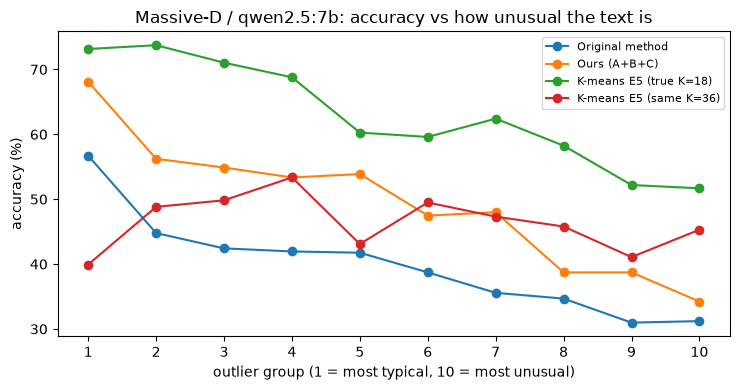

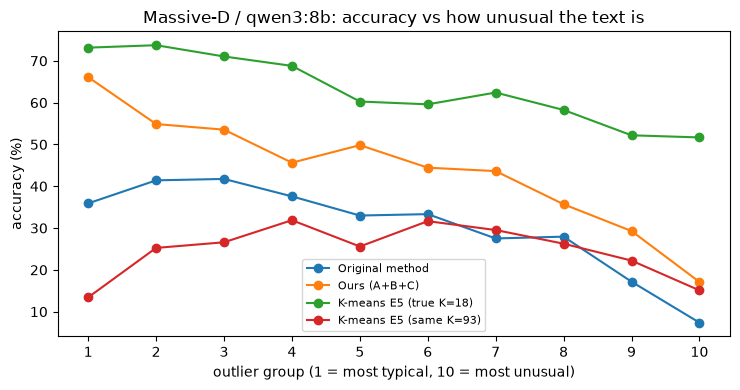

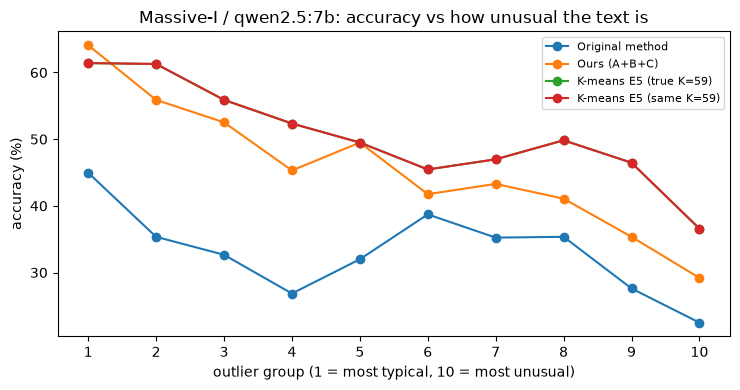

In [7]:
for (data, model), r in RUNS.items():
    dec = pd.qcut(SCORES[data], 10, labels=False) + 1
    plt.figure(figsize=(7.5, 4))
    for method, p in r["preds"].items():
        c = correct_per_text(r["y"], p)
        plt.plot(range(1, 11), [100 * c[dec == d].mean() for d in range(1, 11)], marker="o", label=method)
    plt.xlabel("outlier group (1 = most typical, 10 = most unusual)"); plt.ylabel("accuracy (%)")
    plt.title(f"{NAMES[data]} / {model}: accuracy vs how unusual the text is"); plt.legend(fontsize=8)
    plt.xticks(range(1, 11)); plt.tight_layout()
    plt.savefig(f"./results/figures/outliers_{data}_{model.replace(':', '_')}.png", dpi=200); plt.show()

## Findings (fill in after running)
1. **What the outliers are:** shorter or longer than normal? Which categories have the most (e.g. *general*, *qa* chit-chat)? Do the examples look ambiguous, off-topic or very short?
2. **Effect on scores:** how much does each method's ACC rise when the top 10% outliers are removed? Which method's score depends most on the outliers?
3. **Who handles outliers best:** in the accuracy-by-group chart, does the LLM method (which reads meaning) drop less on unusual texts than K-means (which only uses embedding distance)? Or does it drop more?
4. **Original method:** were its "Unsuccessful" texts concentrated among the outliers? If yes, unusual texts are also where the small LLM fails to answer within the label list.
5. **For the paper:** one sentence on whether outliers explain part of the remaining gap to GPT-3.5, and whether they suggest an improvement (e.g. a separate "other" cluster for very unusual texts, or sending only outliers to a stronger model).